In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [27]:
# Load dataset
wine = load_wine()

# Create DataFrame
X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

print("Dataset shape:", X.shape)
print(X.head())


Dataset shape: (178, 13)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  prol

In [28]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [29]:
print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)
print("First 5 rows:\n", X_scaled[:5])

Original shape: (178, 13)
Scaled shape: (178, 13)
First 5 rows:
 [[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


In [30]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


In [31]:
print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)
print("First 5 rows:\n", X_pca[:5])

Original shape: (178, 13)
Reduced shape: (178, 2)
First 5 rows:
 [[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]]


In [32]:
X_pca

array([[ 3.31675081,  1.44346263],
       [ 2.20946492, -0.33339289],
       [ 2.51674015,  1.0311513 ],
       [ 3.75706561,  2.75637191],
       [ 1.00890849,  0.86983082],
       [ 3.05025392,  2.12240111],
       [ 2.44908967,  1.17485013],
       [ 2.05943687,  1.60896307],
       [ 2.5108743 ,  0.91807096],
       [ 2.75362819,  0.78943767],
       [ 3.47973668,  1.30233324],
       [ 1.7547529 ,  0.61197723],
       [ 2.11346234,  0.67570634],
       [ 3.45815682,  1.13062988],
       [ 4.31278391,  2.09597558],
       [ 2.3051882 ,  1.66255173],
       [ 2.17195527,  2.32730534],
       [ 1.89897118,  1.63136888],
       [ 3.54198508,  2.51834367],
       [ 2.0845222 ,  1.06113799],
       [ 3.12440254,  0.78689711],
       [ 1.08657007,  0.24174355],
       [ 2.53522408, -0.09184062],
       [ 1.64498834, -0.51627893],
       [ 1.76157587, -0.31714893],
       [ 0.9900791 ,  0.94066734],
       [ 1.77527763,  0.68617513],
       [ 1.23542396, -0.08980704],
       [ 2.18840633,

In [33]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance preserved:")
print(pca.explained_variance_ratio_.sum() * 100, "%")

Explained variance ratio:
[0.36198848 0.1920749 ]
Total variance preserved:
55.406338356935294 %


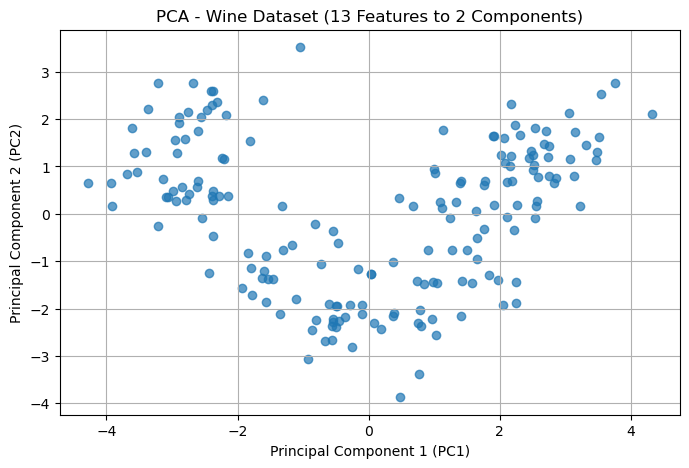

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.7
)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA - Wine Dataset (13 Features to 2 Components)")
plt.grid(True)
plt.show()

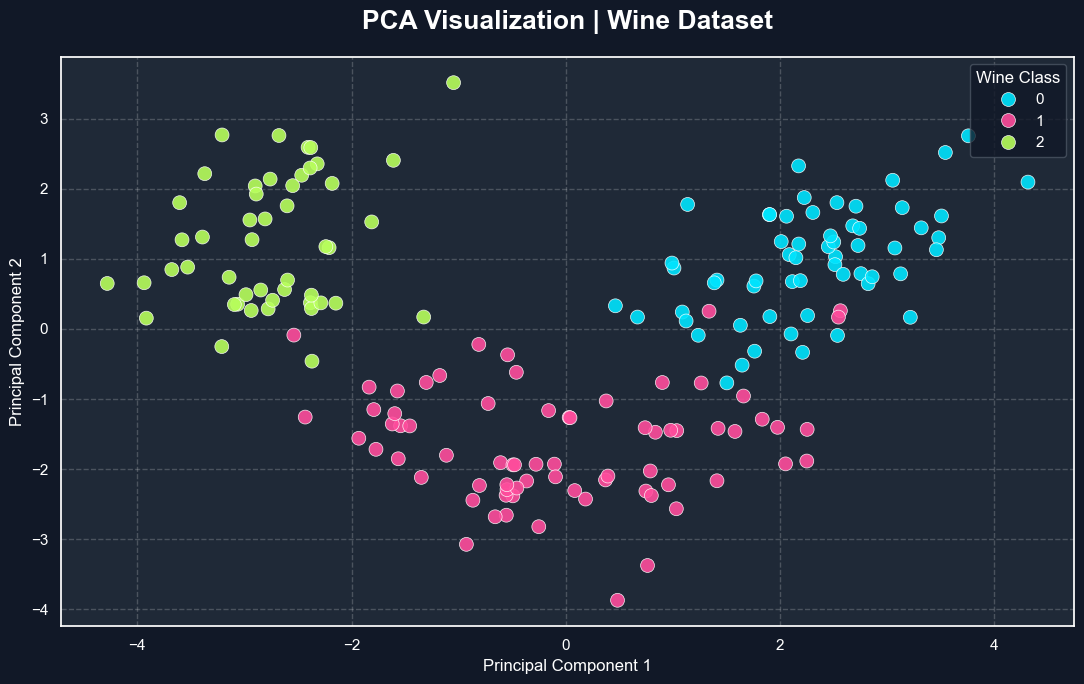

In [34]:
# PCA data + original wine classes
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Wine Class"] = wine.target.astype(str)

# Premium dark theme
sns.set_theme(style="darkgrid", context="notebook")

plt.figure(figsize=(11, 7), facecolor="#111827")
ax = plt.gca()
ax.set_facecolor("#1f2937")

# Attractive scatter plot
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Wine Class",
    palette=["#00E5FF", "#FF4D9D", "#B8FF5C"],
    s=100,
    alpha=0.9,
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

# Styling
plt.title(
    "PCA Visualization | Wine Dataset",
    fontsize=19,
    fontweight="bold",
    color="white",
    pad=20
)

plt.xlabel("Principal Component 1", fontsize=12, color="white")
plt.ylabel("Principal Component 2", fontsize=12, color="white")

plt.xticks(color="white")
plt.yticks(color="white")

ax.grid(True, linestyle="--", alpha=0.2, color="white")

legend = plt.legend(
    title="Wine Class",
    frameon=True,
    facecolor="#111827",
    edgecolor="#4B5563"
)
legend.get_title().set_color("white")

for text in legend.get_texts():
    text.set_color("white")

plt.tight_layout()
plt.show()

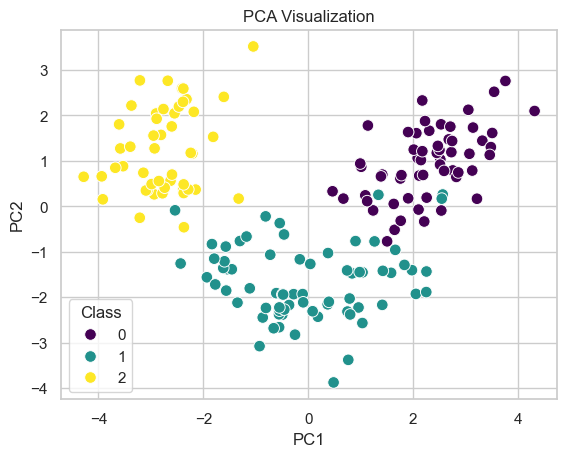

In [35]:
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Class"] = wine.target

sns.set_style("whitegrid")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Class",
    palette="viridis",
    s=70
)

plt.title("PCA Visualization")
plt.show()